# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [17]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [18]:
# a) Display dataset info
df.info()

# b) Print 10 rows from dataset
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1
5,5,116,74,0,0,25.600,0.201,30,0
6,3,78,50,32,88,31.000,0.248,26,1
7,10,115,0,0,0,35.300,0.134,29,0
8,2,197,70,45,543,30.500,0.158,53,1
9,8,125,96,0,0,0.000,0.232,54,1


Step 3 - Write code to remove Pregnancy column 

In [19]:
# In standard diabetes datasets, the column is named 'Pregnancies'
col_to_drop = 'Pregnancies' if 'Pregnancies' in df.columns else 'Pregnancy'
df = df.drop(columns=[col_to_drop])
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.600,0.627,50,1
1,85,66,29,0,26.600,0.351,31,0
2,183,64,0,0,23.300,0.672,32,1
3,89,66,23,94,28.100,0.167,21,0
4,137,40,35,168,43.100,2.288,33,1


Step 4 - Write code to display info of dataset and check shape of dataset.

In [20]:
print("Shape of dataset:", df.shape)
df.info()

Shape of dataset: (768, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


Step 5 - Write code to clean data

In [21]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Replace 0 with NaN first, then fill with median
for col in zero_cols:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)
        df[col] = df[col].fillna(df[col].median())

# Check that missing values are resolved
print("Missing values after cleaning:\n", df.isnull().sum())
df.describe()

Missing values after cleaning:
 Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,121.656,72.387,29.108,140.672,32.455,0.472,33.241,0.349
std,30.438,12.097,8.791,86.383,6.875,0.331,11.760,0.477
min,44.000,24.000,7.000,14.000,18.200,0.078,21.000,0.000
25%,99.750,64.000,25.000,121.500,27.500,0.244,24.000,0.000
50%,117.000,72.000,29.000,125.000,32.300,0.372,29.000,0.000
75%,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000


Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [22]:
# Features (X) and Target (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# 80:20 split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature scaling using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

X_train shape: (614, 7)
X_test shape : (154, 7)


#### **Step #7: Initialize your model**




In [23]:
model = GaussianNB()
print("Model initialized:", model)

Model initialized: GaussianNB()


#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

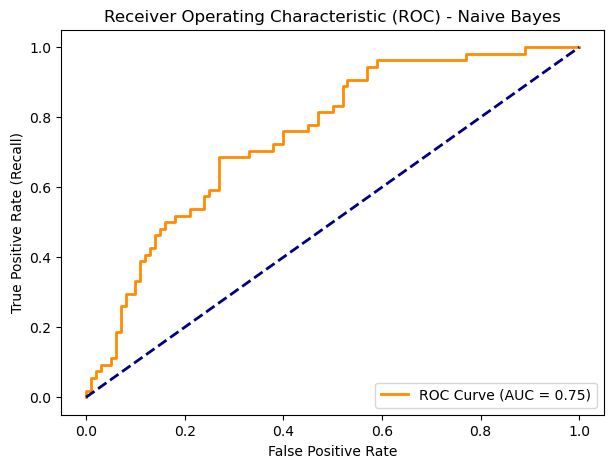

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

# Fit the model
model.fit(X_train, y_train)

# Predict probabilities for ROC curve
y_probs = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)

# Visualization: ROC Curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) - Naive Bayes')
plt.legend(loc="lower right")
plt.show()

Step 9 - Predict using model on test data

In [25]:
y_pred = model.predict(X_test)

# Display sample of actual vs predicted
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
results.head(10)

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,1,1
7,1,1
8,0,0
9,0,1


Step 10 -  Find accuracy of model

In [26]:
acc = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {acc:.4f} ({acc*100:.2f}%)")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))

Model Accuracy: 0.6883 (68.83%)

--- Detailed Classification Report ---
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.75      0.77      0.76       100
    Diabetic (1)       0.56      0.54      0.55        54

        accuracy                           0.69       154
       macro avg       0.66      0.65      0.65       154
    weighted avg       0.69      0.69      0.69       154



Step 11 - Confusion Matrix

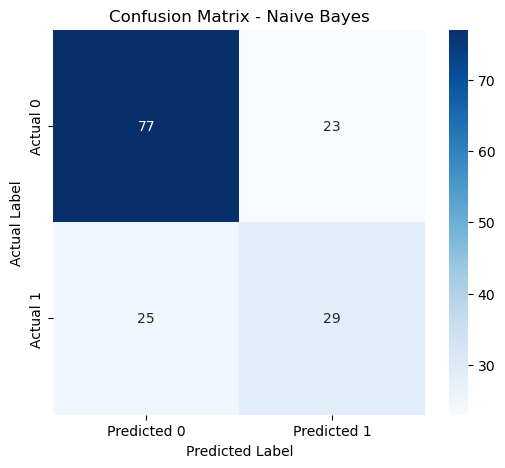

In [27]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix - Naive Bayes')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

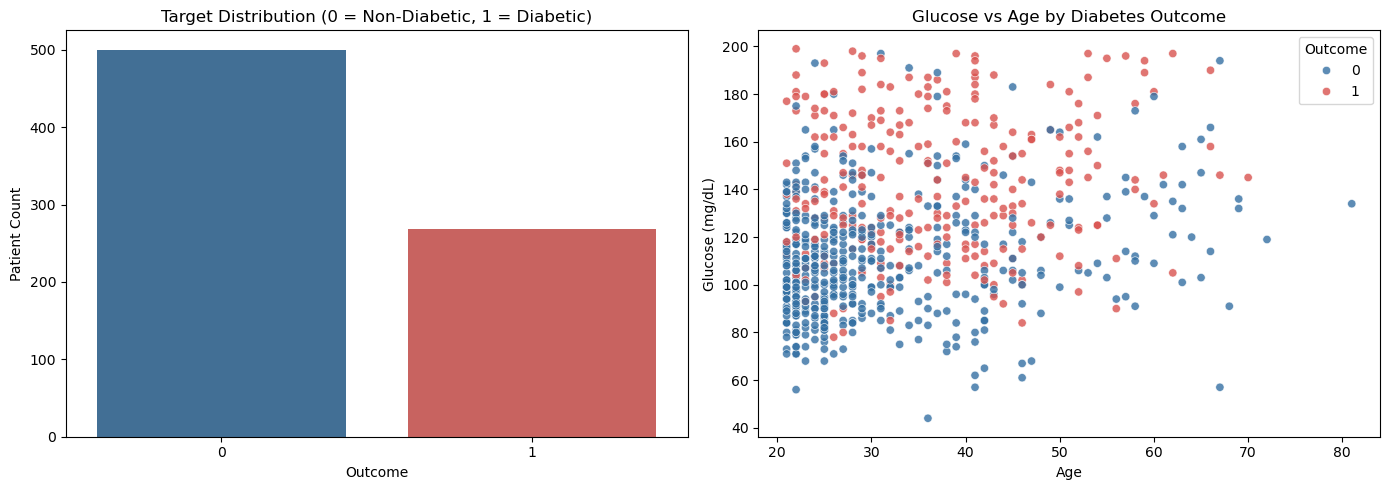

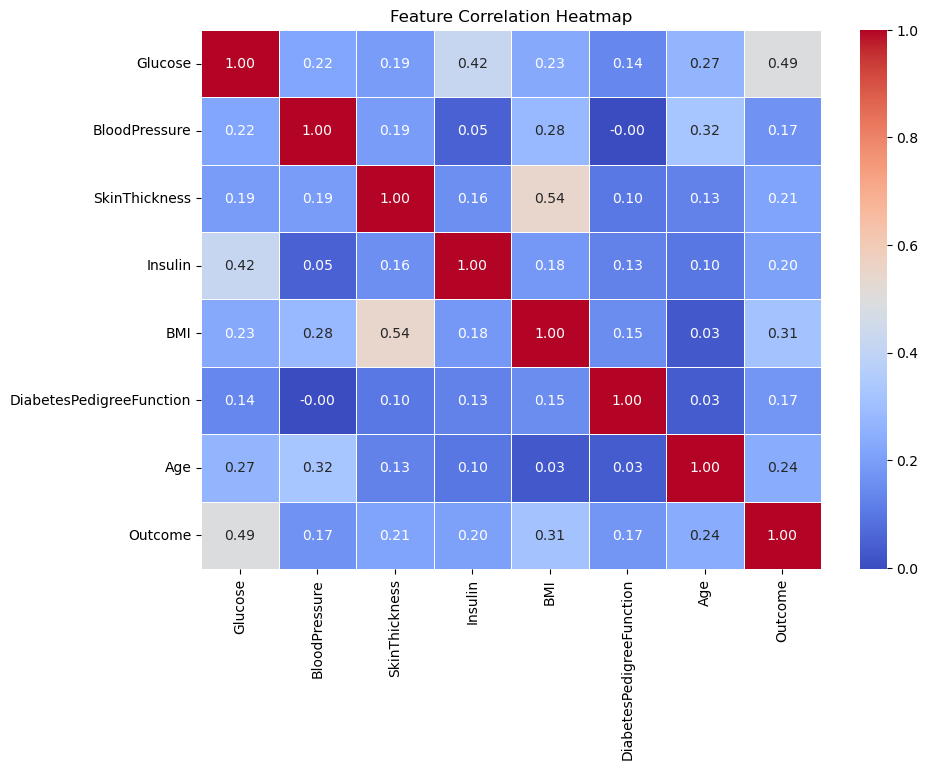

In [28]:
# --- Rubric: Data Exploration Charts (5 pts) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Outcome Distribution
sns.countplot(x='Outcome', data=df, hue='Outcome', palette=['#3470a3', '#d9534f'], legend=False, ax=axes[0])
axes[0].set_title('Target Distribution (0 = Non-Diabetic, 1 = Diabetic)')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Patient Count')

# Chart 2: Glucose vs Age by Diabetes Outcome
sns.scatterplot(x='Age', y='Glucose', hue='Outcome', data=df, palette=['#3470a3', '#d9534f'], alpha=0.8, ax=axes[1])
axes[1].set_title('Glucose vs Age by Diabetes Outcome')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Glucose (mg/dL)')

plt.tight_layout()
plt.show()

# Chart 3: Feature Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()